# FIT5215 / FIT3181 Assignment 1 - Kaggle Starter Notebook

This notebook provides a complete, deliberately simple workflow: download the training data, load the hidden-label Kaggle test set, create a validation split, train a starter CNN, and write a valid Kaggle submission.

The starter notebook is intended to run in **Google Colab with a GPU runtime**. Improve the data augmentation, model architecture, optimization, and validation procedure for your own submission.

## Before you start

1. In Colab, select **Runtime → Change runtime type → GPU**.
2. Make your own copy of this notebook.
3. On the competition **Data** tab, download `test_set.zip` and upload it to the Colab Files pane. When extracted, it creates a `test_set` folder containing the `test_dataset` image folder and the sample submission template `my_solution.csv`.

   **If your computer automatically decompresses the file downloaded from Kaggle, compress the complete extracted `test_set` folder again, name the new archive `test_set.zip`, and upload that ZIP file to Colab.**

4. The labelled training set is downloaded separately from Google Drive. Use the [primary training archive](https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing), or manually switch to the [backup training archive](https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing) if the primary link is unavailable.

The release contains **9,466 labelled training images across 20 classes** and **11,681 unlabelled 64×64 test images**. The submission template contains the columns `ID,Label`. Use only the provided training labels and follow the assignment and competition rules.

In [1]:
from __future__ import annotations

import copy
import os
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.utils import make_grid

SEED = 2026
ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd()
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset.zip'
TRAIN_DIR = ROOT / 'FIT5215_Dataset'
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'

def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Working directory:', ROOT)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type != 'cuda':
    print('Warning: training will be much slower without a GPU runtime.')

Working directory: /content
PyTorch: 2.11.0+cu128
Device: cuda


## 1. Download the labelled training set

Run the primary download below. If that link is unavailable, comment it out and uncomment the backup download. Both commands save the archive with the same filename.

In [2]:
# Primary download
#!gdown --fuzzy 'https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing' -O Animals_Dataset.zip

# Backup download: use this only if the primary link is unavailable.
# !gdown --fuzzy 'https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing' -O Animals_Dataset.zip

!unzip -q -o Animals_Dataset.zip
assert TRAIN_DIR.is_dir(), f'Training folder not found: {TRAIN_DIR}'
print('Training data ready:', TRAIN_DIR)

Training data ready: /content/FIT5215_Dataset


## 2. Load the Kaggle test data and submission template

Upload `test_set.zip` to the Colab Files pane. It must extract into the same layout as the Kaggle download:

```text
test_set.zip
└── test_set/
    ├── test_dataset/
    │   ├── 00000_animal.jpeg
    │   └── ...
    └── my_solution.csv
```

**If your computer automatically decompresses the Kaggle download, compress the complete extracted `test_set` folder again, name the archive `test_set.zip`, and then upload it to Colab.** Keep the names and folder structure unchanged.

In [20]:
EXPECTED_TEST_IMAGES = 11_681

if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    assert TEST_ARCHIVE.is_file(), (
        'Upload test_set.zip to the Colab Files pane before continuing.'
    )
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)

assert TEST_PACKAGE_DIR.is_dir(), (
    'The ZIP must contain a top-level folder named test_set.'
)
assert TEST_DIR.is_dir(), (
    'The test_set folder must contain the test_dataset image folder.'
)
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, (
    f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
)
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), (
    'Test image IDs must run from 0 to 11680.'
)
assert SUBMISSION_TEMPLATE.is_file(), (
    'The test_set folder must contain my_solution.csv.'
)
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())

Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


## 3. Build training, validation, and test datasets

The split is stratified so every class is represented in both training and validation. Training augmentation is intentionally mild because the Kaggle images are only 64×64. Validation and test preprocessing are deterministic.

In [21]:
EXPECTED_CLASS_NAMES = [
  'birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats',
  'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes',
  'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes',
  'spiders', 'vases',
]

CLASS_NAME_CORRECTIONS = {
  'butterfiles': 'butterflies'
}

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
VALIDATION_FRACTION = 0.15

train_transform = transforms.Compose([
  transforms.Resize((64, 64)),
  transforms.RandomResizedCrop(
    300,
    scale=(0.75, 1.0),
    ratio=(0.85, 1.15)
  ),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.RandomRotation(10),
  transforms.ColorJitter(
    brightness=0.15,
    contrast=0.15,
    saturation=0.15,
    hue=0.02
  ),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD),
  transforms.RandomErasing(
    p=0.10,
    scale=(0.02, 0.10),
    ratio=(0.5, 2.0)
  )
])

evaluation_transform = transforms.Compose([
  transforms.Resize((64, 64)),
  transforms.Resize((300, 300)),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD)
])

index_dataset = datasets.ImageFolder(TRAIN_DIR)

class_names = [
  CLASS_NAME_CORRECTIONS.get(name, name)
  for name in index_dataset.classes
]

if class_names != EXPECTED_CLASS_NAMES:
  raise RuntimeError(
    f'Unexpected training class order: {class_names}'
  )

targets = np.asarray(
  index_dataset.targets,
  dtype=np.int64
)

rng = np.random.default_rng(SEED)

train_indices = []
validation_indices = []

for class_index in range(len(class_names)):
  class_indices = np.flatnonzero(
    targets == class_index
  )

  rng.shuffle(class_indices)

  validation_count = max(
    1,
    int(
      round(
        len(class_indices)
        * VALIDATION_FRACTION
      )
    )
  )

  validation_indices.extend(
    class_indices[:validation_count].tolist()
  )

  train_indices.extend(
    class_indices[validation_count:].tolist()
  )

train_indices = sorted(train_indices)
validation_indices = sorted(validation_indices)

training_augmented = datasets.ImageFolder(
  TRAIN_DIR,
  transform=train_transform
)

training_evaluation = datasets.ImageFolder(
  TRAIN_DIR,
  transform=evaluation_transform
)

train_dataset = Subset(
  training_augmented,
  train_indices
)

train_evaluation_dataset = Subset(
  training_evaluation,
  train_indices
)

validation_dataset = Subset(
  training_evaluation,
  validation_indices
)

class KaggleTestDataset(Dataset):
  def __init__(self, paths: list[Path], transform):
    self.paths = paths
    self.transform = transform

  def __len__(self) -> int:
    return len(self.paths)

  def __getitem__(self, index: int):
    path = self.paths[index]

    test_id = int(
      path.name.split('_', 1)[0]
    )

    with Image.open(path) as image:
      tensor = self.transform(
        image.convert('RGB')
      )

    return tensor, test_id

test_dataset = KaggleTestDataset(
  test_paths,
  evaluation_transform
)

print('Classes:', class_names)

Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']


In [22]:
BATCH_SIZE = 32
NUM_WORKERS = min(2, os.cpu_count() or 1)
pin_memory = device.type == 'cuda'

loader_generator = torch.Generator().manual_seed(SEED)

def seed_worker(worker_id: int) -> None:
  worker_seed = torch.initial_seed() % (2**32)
  np.random.seed(worker_seed)
  random.seed(worker_seed)

train_loader = DataLoader(
  train_dataset,
  batch_size=BATCH_SIZE,
  shuffle=True,
  generator=loader_generator,
  worker_init_fn=seed_worker,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

train_evaluation_loader = DataLoader(
  train_evaluation_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

validation_loader = DataLoader(
  validation_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

test_loader = DataLoader(
  test_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

print(f'Train: {len(train_dataset):,}')
print(f'Validation: {len(validation_dataset):,}')
print(f'Test: {len(test_dataset):,}')

Train: 8,047
Validation: 1,419
Test: 11,681


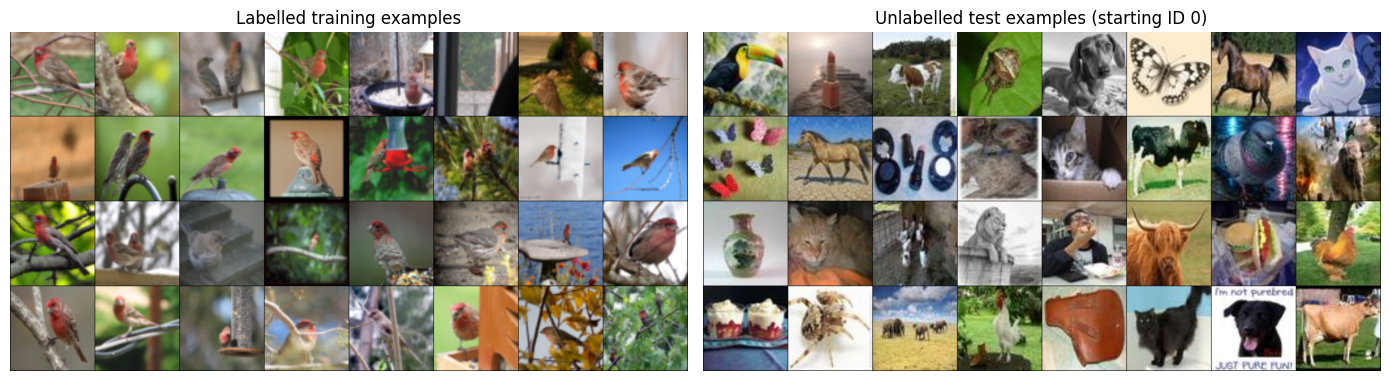

Example training label: birds


In [23]:
def denormalize(batch: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_evaluation_loader))
test_images, displayed_test_ids = next(iter(test_loader))
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(make_grid(denormalize(images[:32]), nrow=8).permute(1, 2, 0))
axes[0].set_title('Labelled training examples')
axes[0].axis('off')
axes[1].imshow(make_grid(denormalize(test_images[:32]), nrow=8).permute(1, 2, 0))
axes[1].set_title(f'Unlabelled test examples (starting ID {int(displayed_test_ids[0])})')
axes[1].axis('off')
figure.tight_layout()
plt.show()
print('Example training label:', class_names[int(labels[0])])

## 4. Define a starter CNN

This compact network is a starting point, not a target solution. You are expected to make and justify your own improvements within the assignment rules.

In [24]:
from torchvision.models import (
  efficientnet_b3,
  EfficientNet_B3_Weights
)

seed_everything(SEED)

weights = EfficientNet_B3_Weights.DEFAULT
model = efficientnet_b3(weights=weights)

for parameter in model.features.parameters():
  parameter.requires_grad = False

num_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
  nn.Dropout(p=0.30),
  nn.Linear(num_features, len(class_names))
)

model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 200MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1536, out_features=20, bias=True)
)


## 5. Train and select the best validation checkpoint

Only validation performance is used for model selection. The Kaggle test set remains unlabelled and is used once for final prediction.

In [25]:
def run_epoch(
  model,
  loader,
  loss_function,
  optimizer=None
):
  training = optimizer is not None

  model.train(training)

  if training:
    # During head training, keep the frozen features deterministic.
    backbone_frozen = not any(
      parameter.requires_grad
      for parameter in model.features.parameters()
    )

    if backbone_frozen:
      model.features.eval()

    # Preserve BatchNorm running statistics in both stages.
    for module in model.modules():
      if isinstance(module, nn.BatchNorm2d):
        module.eval()

  total_loss = 0.0
  total_correct = 0
  total_examples = 0

  for images, labels in loader:
    images = images.to(
      device=device,
      dtype=torch.float32,
      non_blocking=True
    )

    labels = labels.to(
      device=device,
      dtype=torch.long,
      non_blocking=True
    )

    if training:
      optimizer.zero_grad(
        set_to_none=True
      )

    with torch.set_grad_enabled(training):
      logits = model(images)

      loss = loss_function(
        logits,
        labels
      )

      if training:
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
          model.parameters(),
          max_norm=5.0
        )

        optimizer.step()

    batch_size = labels.size(0)

    total_loss += (
      loss.item() * batch_size
    )

    total_correct += int(
      (
        logits.argmax(dim=1)
        == labels
      ).sum()
    )

    total_examples += batch_size

  return (
    total_loss / total_examples,
    total_correct / total_examples
  )


def fit(
  model,
  train_loader,
  validation_loader,
  loss_function,
  optimizer,
  epochs
):
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-6
  )

  history = []

  best_score = (
    -1.0,
    float('-inf')
  )

  best_state = None
  best_epoch = 0

  for epoch in range(
    1,
    epochs + 1
  ):
    train_loss, train_accuracy = run_epoch(
      model,
      train_loader,
      loss_function,
      optimizer
    )

    validation_loss, validation_accuracy = run_epoch(
      model,
      validation_loader,
      loss_function
    )

    learning_rate = float(
      optimizer.param_groups[0]['lr']
    )

    history.append({
      'epoch': epoch,
      'train_loss': train_loss,
      'train_accuracy': train_accuracy,
      'validation_loss': validation_loss,
      'validation_accuracy': validation_accuracy,
      'learning_rate': learning_rate
    })

    score = (
      validation_accuracy,
      -validation_loss
    )

    if score > best_score:
      best_score = score
      best_state = copy.deepcopy(
        model.state_dict()
      )
      best_epoch = epoch

    print(
      f'Epoch {epoch:02d}/{epochs:02d} | '
      f'train loss {train_loss:.4f}, '
      f'acc {train_accuracy:.2%} | '
      f'val loss {validation_loss:.4f}, '
      f'acc {validation_accuracy:.2%} | '
      f'lr {learning_rate:.6f}'
    )

    scheduler.step()

  return (
    pd.DataFrame(history),
    best_state,
    best_epoch
  )

In [26]:
HEAD_EPOCHS = 5
HEAD_LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

loss_function = nn.CrossEntropyLoss(
  label_smoothing=0.05
)

optimizer = torch.optim.AdamW(
  model.classifier.parameters(),
  lr=HEAD_LEARNING_RATE,
  weight_decay=WEIGHT_DECAY
)

head_history, head_best_state, head_best_epoch = fit(
  model,
  train_loader,
  validation_loader,
  loss_function,
  optimizer,
  HEAD_EPOCHS
)

model.load_state_dict(head_best_state)

head_validation_loss, head_validation_accuracy = run_epoch(
  model,
  validation_loader,
  loss_function
)

print(f"Best head-training epoch: {head_best_epoch}")
print(
  f"Best head validation accuracy: "
  f"{head_validation_accuracy:.2%}"
)

Epoch 01/05 | train loss 0.9070, acc 91.25% | val loss 0.4878, acc 97.11% | lr 0.001000
Epoch 02/05 | train loss 0.4961, acc 96.23% | val loss 0.4598, acc 97.11% | lr 0.000905
Epoch 03/05 | train loss 0.4674, acc 97.15% | val loss 0.4524, acc 97.39% | lr 0.000655
Epoch 04/05 | train loss 0.4572, acc 97.39% | val loss 0.4503, acc 97.46% | lr 0.000346
Epoch 05/05 | train loss 0.4455, acc 97.96% | val loss 0.4495, acc 97.46% | lr 0.000096
Best head-training epoch: 5
Best head validation accuracy: 97.46%


In [27]:
model.load_state_dict(head_best_state)

# Allow the pretrained feature weights to adapt.
for parameter in model.features.parameters():
  parameter.requires_grad = True

optimizer = torch.optim.AdamW([
  {
    "params": model.features.parameters(),
    "lr": 1e-5
  },
  {
    "params": model.classifier.parameters(),
    "lr": 1e-4
  }
], weight_decay=1e-4)

FINE_TUNE_EPOCHS = 10

fine_history, fine_best_state, fine_best_epoch = fit(
  model,
  train_loader,
  validation_loader,
  loss_function,
  optimizer,
  FINE_TUNE_EPOCHS
)

model.load_state_dict(fine_best_state)

fine_validation_loss, fine_validation_accuracy = run_epoch(
  model,
  validation_loader,
  loss_function
)

print(f"Best fine-tuning epoch: {fine_best_epoch}")
print(
  f"Best fine-tuning validation accuracy: "
  f"{fine_validation_accuracy:.2%}"
)

# Keep the better checkpoint across both training stages.
head_score = (
  head_validation_accuracy,
  -head_validation_loss
)

fine_score = (
  fine_validation_accuracy,
  -fine_validation_loss
)

if head_score > fine_score:
  selected_state = head_best_state
  selected_stage = "head"
  selected_epoch = head_best_epoch
else:
  selected_state = fine_best_state
  selected_stage = "fine_tuning"
  selected_epoch = fine_best_epoch

model.load_state_dict(selected_state)

validation_loss, validation_accuracy = run_epoch(
  model,
  validation_loader,
  loss_function
)

print(f"Selected stage: {selected_stage}")
print(
  f"Selected validation accuracy: "
  f"{validation_accuracy:.2%}"
)

Epoch 01/10 | train loss 0.4399, acc 97.97% | val loss 0.4148, acc 98.52% | lr 0.000010
Epoch 02/10 | train loss 0.4136, acc 98.46% | val loss 0.4061, acc 98.31% | lr 0.000010
Epoch 03/10 | train loss 0.4015, acc 98.74% | val loss 0.4003, acc 98.38% | lr 0.000009
Epoch 04/10 | train loss 0.3926, acc 99.03% | val loss 0.3954, acc 98.52% | lr 0.000008
Epoch 05/10 | train loss 0.3844, acc 99.37% | val loss 0.3928, acc 98.59% | lr 0.000007
Epoch 06/10 | train loss 0.3763, acc 99.54% | val loss 0.3900, acc 98.66% | lr 0.000005
Epoch 07/10 | train loss 0.3786, acc 99.35% | val loss 0.3882, acc 98.52% | lr 0.000004
Epoch 08/10 | train loss 0.3749, acc 99.48% | val loss 0.3869, acc 98.73% | lr 0.000003
Epoch 09/10 | train loss 0.3743, acc 99.39% | val loss 0.3862, acc 98.66% | lr 0.000002
Epoch 10/10 | train loss 0.3744, acc 99.44% | val loss 0.3860, acc 98.80% | lr 0.000001
Best fine-tuning epoch: 10
Best fine-tuning validation accuracy: 98.80%
Selected stage: fine_tuning
Selected validation 

In [28]:
full_image_transform = transforms.Compose([
  transforms.Resize((64, 64)),
  transforms.Resize((224, 224)),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD)
])

full_image_source = datasets.ImageFolder(
  TRAIN_DIR,
  transform=full_image_transform
)

full_image_validation = Subset(
  full_image_source,
  validation_indices
)

full_image_loader = DataLoader(
  full_image_validation,
  batch_size=BATCH_SIZE,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

model.load_state_dict(fine_best_state)

crop_loss, crop_accuracy = run_epoch(
  model,
  validation_loader,
  loss_function
)

full_loss, full_accuracy = run_epoch(
  model,
  full_image_loader,
  loss_function
)

print(
  f"Centre crop: accuracy={crop_accuracy:.2%}, "
  f"loss={crop_loss:.4f}"
)
print(
  f"Full image: accuracy={full_accuracy:.2%}, "
  f"loss={full_loss:.4f}"
)

Centre crop: accuracy=98.80%, loss=0.3860
Full image: accuracy=97.67%, loss=0.4221


In [29]:
checkpoint_path = ROOT / "efficientnet_b3_64px_best.pt"

torch.save(
  {
    "architecture": "efficientnet_b3",
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "selected_stage": selected_stage,
    "best_epoch": selected_epoch,
    "validation_accuracy": validation_accuracy,
    "preprocessing": {
      "source_size": 64,
      "input_size": 300,
      "center_crop": False,
      "mean": MEAN,
      "std": STD
    }
  },
  checkpoint_path
)

print("Checkpoint:", checkpoint_path)

Checkpoint: /content/efficientnet_b3_64px_best.pt


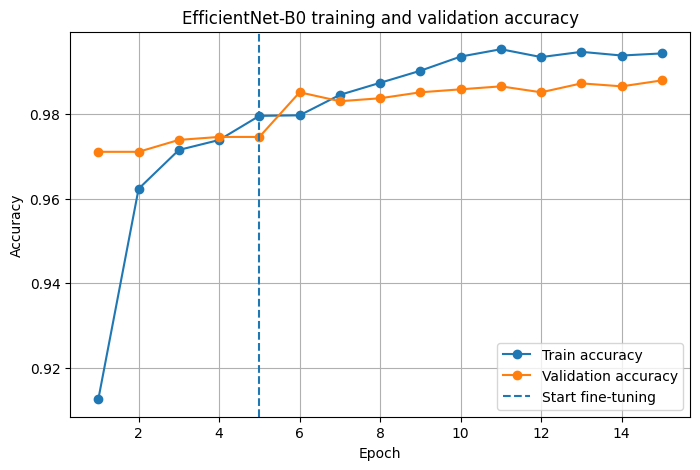

In [30]:
head_plot = head_history.copy()
head_plot['stage'] = 'Head training'

fine_plot = fine_history.copy()
fine_plot['epoch'] = fine_plot['epoch'] + len(head_plot)
fine_plot['stage'] = 'Fine-tuning'

full_history = pd.concat(
  [head_plot, fine_plot],
  ignore_index=True
)

plt.figure(figsize=(8, 5))

plt.plot(
  full_history['epoch'],
  full_history['train_accuracy'],
  marker='o',
  label='Train accuracy'
)

plt.plot(
  full_history['epoch'],
  full_history['validation_accuracy'],
  marker='o',
  label='Validation accuracy'
)

plt.axvline(
  x=len(head_plot),
  linestyle='--',
  label='Start fine-tuning'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('EfficientNet-B0 training and validation accuracy')
plt.legend()
plt.grid(True)
plt.show()

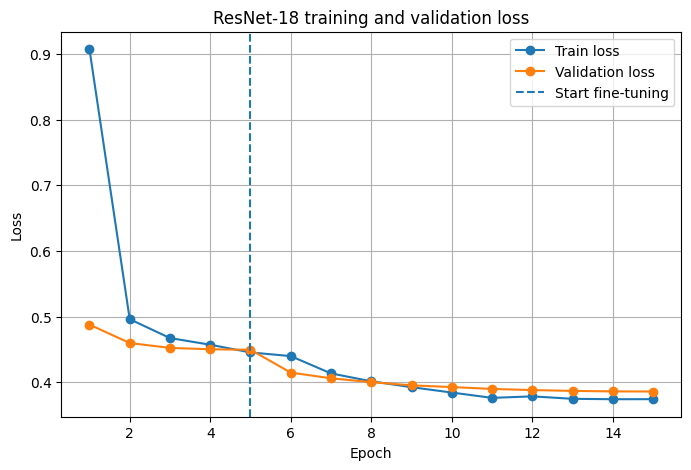

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
  full_history['epoch'],
  full_history['train_loss'],
  marker='o',
  label='Train loss'
)

plt.plot(
  full_history['epoch'],
  full_history['validation_loss'],
  marker='o',
  label='Validation loss'
)

plt.axvline(
  x=len(head_plot),
  linestyle='--',
  label='Start fine-tuning'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ResNet-18 training and validation loss')
plt.legend()
plt.grid(True)
plt.show()

## 6. Predict the test set and create `submission.csv`

Kaggle expects exactly 11,681 rows with the string columns `ID,Label`. Prediction IDs are carried through the data loader and merged into the public template, so batching cannot silently reorder the submission.

In [32]:
test_dataset = KaggleTestDataset(
  test_paths,
  evaluation_transform
)

test_loader = DataLoader(
  test_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

model.load_state_dict(fine_best_state)
model.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
            (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActiv

In [38]:
@torch.inference_mode()
def predict_flip_averaging(model, loader):
  model.eval()

  predicted_ids = []
  predicted_indices = []

  for images, image_ids in loader:
    images = images.to(
      device=device,
      dtype=torch.float32,
      non_blocking=True
    )

    normal_probs = model(images).softmax(dim=1)

    flipped_images = torch.flip(images, dims=[3])
    flipped_probs = model(flipped_images).softmax(dim=1)

    averaged_probs = (
      normal_probs + flipped_probs
    ) / 2

    predicted_indices.extend(
      averaged_probs.argmax(dim=1).cpu().tolist()
    )

    predicted_ids.extend(
      image_ids.cpu().tolist()
    )

  return predicted_ids, predicted_indices


model.load_state_dict(selected_state)

<All keys matched successfully>

In [39]:
@torch.inference_mode()
def predict(model, loader):
    model.eval()
    predicted_ids = []
    predicted_indices = []
    for images, image_ids in loader:
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        predicted_indices.extend(model(images).argmax(dim=1).cpu().tolist())
        predicted_ids.extend(image_ids.tolist())
    return predicted_ids, predicted_indices

predicted_ids, predicted_indices = predict_flip_averaging(
  model,
  test_loader
)
prediction_frame = pd.DataFrame({
    'ID': predicted_ids,
    'Label': [class_names[index] for index in predicted_indices],
})
if prediction_frame['ID'].duplicated().any():
    raise RuntimeError('Predictions contain duplicate IDs.')
if set(prediction_frame['Label']) - set(EXPECTED_CLASS_NAMES):
    raise RuntimeError('Predictions contain an invalid class label.')

submission = submission_template[['ID']].merge(
    prediction_frame, on='ID', how='left', validate='one_to_one'
)
if submission.columns.tolist() != ['ID', 'Label']:
    raise RuntimeError('Submission must contain exactly ID,Label.')
if len(submission) != EXPECTED_TEST_IMAGES or submission['Label'].isna().any():
    raise RuntimeError('Submission rows do not match the test set.')
if submission['ID'].tolist() != list(range(EXPECTED_TEST_IMAGES)):
    raise RuntimeError('Submission IDs are not ordered from 0 to 11680.')

SUBMISSION_PATH = ROOT / 'efficientnet_b3_flip_submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False)
print('Submission:', SUBMISSION_PATH)
print('Rows:', len(submission))
display(submission.head())
display(submission['Label'].value_counts().sort_index())

Submission: /content/efficientnet_b3_flip_submission.csv
Rows: 11681


,ID,Label
0,0,dogs
1,1,lipsticks
2,2,cows
3,3,spiders
4,4,dogs


,count
Label,
birds,149
bottles,371
breads,203
butterflies,924
cakes,284
cats,975
chickens,802
cows,1019
dogs,795


In [40]:
prediction_summary = (
  submission["Label"]
  .value_counts()
  .rename_axis("Class")
  .reset_index(name="Count")
)

prediction_summary["Percentage"] = (
  prediction_summary["Count"]
  / len(submission)
  * 100
).round(2)

display(prediction_summary)

,Class,Count,Percentage
0,spiders,1163,9.96
1,elephants,1084,9.28
2,cows,1019,8.72
3,cats,975,8.35
4,butterflies,924,7.91
5,chickens,802,6.87
6,dogs,795,6.81
7,horses,752,6.44
8,vases,699,5.98
9,ducks,435,3.72


## 7. Submit and improve

Download `submission.csv`, open your cohort's Kaggle competition, choose **Submit Predictions**, and upload the CSV. Do not upload the unchanged `my_solution.csv` placeholder.

Useful next experiments include stronger but still mild augmentation, deeper model architectures, regularization, learning-rate schedules, class-balanced sampling, and permitted pretrained models. Keep the validation split fixed while comparing experiments, and preserve the exact test IDs and canonical string labels.

In [41]:
# Run this cell in Google Colab to download the completed submission.
try:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))
except ImportError:
    print(f'Not running in Colab. Submission is saved at {SUBMISSION_PATH}.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>